In [5]:
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import random
%matplotlib inline

In [6]:
class Value:
    
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self._backward = lambda: None

        # By default 0 because it has no impact on the loss function
        self.grad = 0.0

    def __repr__(self):
        return f"Value(data={self.data})"

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += out.grad
            other.grad += out.grad
        out._backward = _backward

        return out

    def __radd__(self, other):
        return self + other

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data
        out._backward = _backward

        return out

    def __rmul__(self, other):
        return self*other

    def __truediv__(self, other):
        return self*other**-1

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "Only supporting int/float powers"
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += out.grad * other * self.data**(other - 1)
        out._backward = _backward

        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad += out.data*out.grad
        out._backward = _backward

        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, (self,), 'tanh')

        def _backward():
            self.grad += out.grad * (1 - t**2)
        out._backward = _backward

        return out

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)
        for node in reversed(topo):
            node._backward()

In [7]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid, label=f"{{ {n.label} | data: {n.data:.4f} | grad: {n.grad:.4f} }}", shape='record')

        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


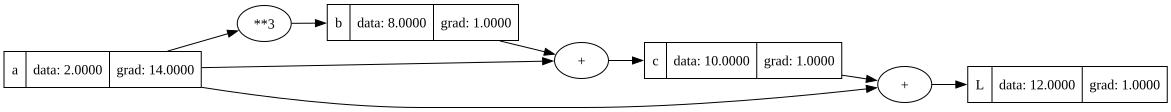

In [4]:
a = Value(2.0, label='a')
b = a ** 3; b.label = 'b'
c = a + b; c.label = 'c'
L = a + c; L.label = 'L'
L.grad = 1.0
L.backward()
draw_dot(L)

In [5]:
# Input
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# Weight
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# Bias
b = Value(6.881317762999999, label='b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

out = n.tanh(); out.label = 'out'

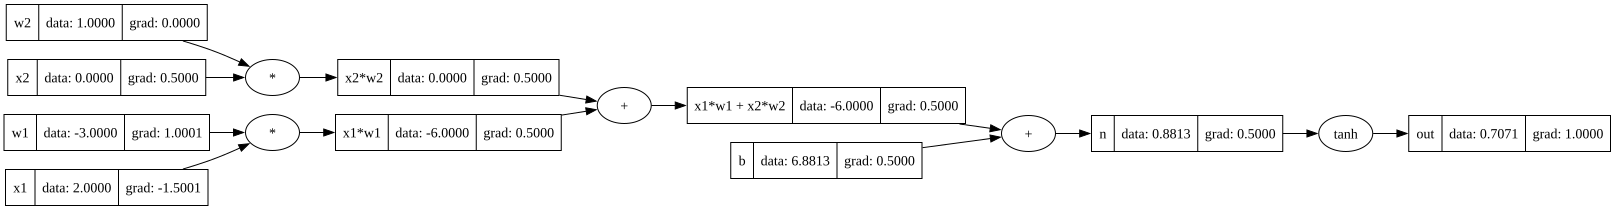

In [7]:
draw_dot(out)

In [6]:
out.grad = 1.0
out.backward()

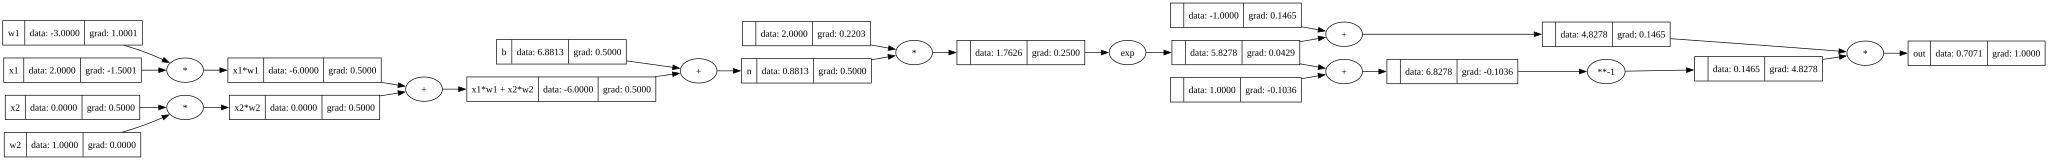

In [8]:
# Input
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# Weight
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# Bias
b = Value(6.881317762999999, label='b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

e = (2*n).exp()
out = (e - 1) / (e + 1); out.label = 'out'
out.grad = 1.0
out.backward()
draw_dot(out)

In [13]:
x1 = torch.Tensor([2.0]).double()               ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()               ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()              ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()               ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double() ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
out = torch.tanh(n)

print(out.data.item())
out.backward()

print('----')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
----
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [8]:
class Neuron:

    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        activation = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        return activation.tanh()

    def parameters(self):
        return self.w + [self.b]
    
    def zero_grad(self):
        for w in self.w:
            w.grad = 0.0
        self.b.grad = 0.0

class Layer:

    def __init__(self, nin, nout):
        # nin is number of inputs for each neuron
        # nout is the number of neurons in the layer
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

    def zero_grad(self):
        for neuron in self.neurons:
            neuron.zero_grad()

class MLP:
    # Multi-layer Perceptron

    def __init__(self, nin, nouts):
        # nin is the size of the input layer
        # nouts is a list which defines the size of every layer in the MLP
        sz = [nin] + nouts

        # Note that the input layer does NOT count as a neuron layer
        # hence why it is separate as `nin` from the `nouts` list
        self.layers = [Layer(sz[i], sz[i + 1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [param for layer in self.layers for param in layer.parameters()]

    def zero_grad(self):
        for layer in self.layers:
            layer.zero_grad()

In [9]:
x = [2.0, 1.0, 3.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=-0.24742804981255861)

In [127]:
len(n.parameters())

41

In [10]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]

# Desired targets
ys = [1.0, -1.0, -1.0, 1.0]

In [13]:
for k in range(20):
    # Forward Pass
    # The only way for the expression in the sum to equal 0 is if the prediction equals the target
    # ygt is y ground-target, which is just ys
    ypred = [n(x) for x in xs]
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
    loss.grad = 1.0

    # Backward Pass
    n.zero_grad() # Could also just iterate through every n.parameters() and manually set to 0.0
    loss.backward()

    # Tweak parameters
    for param in n.parameters():
        # You want negative because there are two cases:
        # 1. If param.grad > 0, you want to step BACKWARDS which would decrease the loss
        # 2. If param.grad < 0, you want to step FORWARD which would decrease the loss
        param.data += -0.05 * param.grad

    print(k, loss.data)

0 0.024082441901954837
1 0.023385995352129763
2 0.022726550762497737
3 0.02210130369655283
4 0.021507722258006987
5 0.020943515077193654
6 0.020406603675378547
7 0.019895098527817505
8 0.019407278263679346
9 0.01894157153601428
10 0.018496541172350726
11 0.01807087027981696
12 0.01766335003068478
13 0.017272868897121037
14 0.016898403139441746
15 0.01653900838167305
16 0.01619381213283847
17 0.01586200713299165
18 0.015542845420314057
19 0.01523563303017246
